# Leyenda — Deliverable 1: photo vs non-photo

TouNum digitises large collections of images and needs to tell photographs apart from everything else, so that only photos go on to the next steps of its pipeline.
The task is binary: Photo = 1 against Painting, Schematics, Sketch and Text = 0.
This notebook goes from simple baselines (majority class, a decision tree on image format) to an MLP, a CNN trained from scratch with improvements, and a pretrained MobileNetV2.

In [1]:
import io
import os
import time
import hashlib
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image
import sklearn
from sklearn.metrics import (average_precision_score, balanced_accuracy_score,
                             confusion_matrix, precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import tensorflow as tf
import keras
from IPython.display import Image as ShowImage

T0 = time.time()
gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    raise SystemExit("No GPU found by TensorFlow: check the kernel and the CUDA libraries (see README) before running this notebook.")
tf.config.experimental.set_memory_growth(gpus[0], True)
GPU_NAME = tf.config.experimental.get_device_details(gpus[0]).get("device_name", "unknown")
print("GPU:", GPU_NAME)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| Pillow", PIL.__version__)

DATA_DIR, CACHE, REPORTS, MODELS = Path("data/Datasets"), Path("cache"), Path("reports"), Path("models")
for d in [CACHE, REPORTS, MODELS]:
    d.mkdir(exist_ok=True)
SEED, SIZE, BATCH, MIN_SIDE_PX, NOISE = 42, 128, 32, 32, 0.03
METRICS = ["precision", "recall", "f1", "balanced_acc", "pr_auc", "accuracy"]

I0000 00:00:1791540603.145530  177147 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791540604.530160  177147 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: NVIDIA GeForce RTX 5060 Laptop GPU
TensorFlow 2.22.0-rc0 | Keras 3.16.0.dev2026100504 | numpy 2.5.3 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2 | Pillow 12.3.0


## Helpers

These functions are copied from utils.py so that the notebook runs on its own.

In [2]:
def _load_one(path, size):
    with Image.open(DATA_DIR / path) as im:
        return np.asarray(im.convert("RGB").resize((size, size), Image.BILINEAR), dtype=np.uint8)

def load_images(df, size=128):
    """RGB uint8 array (n, size, size, 3), cached in cache/ (key = list of paths + size)."""
    key = hashlib.md5(("|".join(df["path"]) + f"|{size}").encode()).hexdigest()[:12]
    fp = CACHE / f"images_{size}_{len(df)}_{key}.npy"
    if fp.exists():
        return np.load(fp)
    with ThreadPoolExecutor(8) as ex:
        X = np.stack(list(ex.map(lambda p: _load_one(p, size), df["path"])))
    np.save(fp, X)
    return X

def class_weights(y_train):
    """Balanced weights n / (2 * n_c), from training labels only."""
    n, n1 = len(y_train), int(np.sum(y_train))
    return {0: n / (2 * (n - n1)), 1: n / (2 * n1)}

def evaluate(y_true, proba, origin, threshold=0.5):
    """Photo-class metrics at a fixed threshold, plus error rate by origin."""
    y_true, proba = np.asarray(y_true), np.asarray(proba).ravel()
    y_pred = (proba >= threshold).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[1], zero_division=0)
    err = pd.Series(y_pred != y_true, index=np.asarray(origin)).groupby(level=0).mean()
    return {"precision": p[0], "recall": r[0], "f1": f[0],
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "pr_auc": average_precision_score(y_true, proba),
            "accuracy": (y_pred == y_true).mean(),
            "cm": confusion_matrix(y_true, y_pred, labels=[0, 1]),
            "error_by_origin": err}

def plot_curves(history, title="", axes=None):
    """Train/validation loss and accuracy per epoch from a Keras history dict."""
    if axes is None:
        _, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    epochs = np.arange(1, len(history["loss"]) + 1)
    for ax, m in zip(axes, ["loss", "accuracy"]):
        ax.plot(epochs, history[m], color="#2a78d6", lw=2, marker="o", ms=4, label="train")
        ax.plot(epochs, history[f"val_{m}"], color="#eb6834", lw=2, marker="o", ms=4, label="validation")
        ax.set(title=f"{title} - {m}".strip(" -"), xlabel="epoch")
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(frameon=False)
    return axes

## 2. Data processing

Every file of the 5 folders is read once: MD5 of the bytes, width, height, colour mode, and a full decode to catch truncated files.
The result is cached in cache/ because reading 41,000 files takes about a minute.

In [3]:
def inspect(fp):
    data = fp.read_bytes()
    row = {"md5": hashlib.md5(data).hexdigest(), "width": np.nan, "height": np.nan, "mode": "", "drop_reason": ""}
    if fp.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        row["drop_reason"] = "not_an_image"
        return row
    try:
        with Image.open(io.BytesIO(data)) as im:
            row["width"], row["height"], row["mode"] = im.size[0], im.size[1], im.mode
            im.load()  # decodes every pixel
    except Exception:
        row["drop_reason"] = "unreadable"
    return row

ORIGINS = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())
files = [(o, fp) for o in ORIGINS for fp in sorted((DATA_DIR / o).iterdir()) if fp.is_file()]
paths = [fp.relative_to(DATA_DIR).as_posix() for _, fp in files]
inv_cache = CACHE / f"inventory_{len(files)}_{hashlib.md5('|'.join(paths).encode()).hexdigest()[:12]}.csv"
if inv_cache.exists():
    df = pd.read_csv(inv_cache, dtype={"md5": str, "mode": str, "drop_reason": str})
    df[["mode", "drop_reason"]] = df[["mode", "drop_reason"]].fillna("")
else:
    with ThreadPoolExecutor(16) as ex:
        df = pd.DataFrame(list(ex.map(lambda t: inspect(t[1]), files)))
    df.insert(0, "path", paths)
    df.insert(1, "origin", [o for o, _ in files])
    df.insert(2, "label", (df["origin"] == "Photo").astype(int))
    df.insert(3, "ext", [fp.suffix.lower().lstrip(".") for _, fp in files])
    df.to_csv(inv_cache, index=False)

print(f"{len(df)} files, {(df['drop_reason'] != '').sum()} not an image or unreadable")
display(pd.crosstab(df["origin"], df["ext"], margins=True, margins_name="total"))
display(pd.crosstab(df["origin"], df["mode"], margins=True, margins_name="total"))
df["min_side"] = df[["width", "height"]].min(axis=1)
df.groupby("origin")["min_side"].describe(percentiles=[0.01, 0.5])[["min", "1%", "50%", "max"]].astype(int)

41399 files, 0 not an image or unreadable


ext,jpg,png,total
origin,,,
Painting,10000,0,10000
Photo,9993,0,9993
Schematics,10000,0,10000
Sketch,606,800,1406
Text,10000,0,10000
total,40599,800,41399


mode,CMYK,L,P,RGB,RGBA,total
origin,,,,,,
Painting,1,82,5,9907,5,10000
Photo,0,25,0,9968,0,9993
Schematics,0,116,0,9884,0,10000
Sketch,0,868,0,538,0,1406
Text,0,0,0,10000,0,10000
total,1,1091,5,40297,5,41399


,min,1%,50%,max
origin,,,,
Painting,201,317,712,6232
Photo,109,281,428,640
Schematics,1,3,441,7273
Sketch,411,411,1111,1111
Text,360,360,595,612


Exact duplicates share the same MD5: the first path in alphabetical order is kept, the others are dropped, and a group with two labels would be dropped entirely.
Images whose shortest side is under MIN_SIDE_PX = 32 px are dropped: they are 1-pixel lines or tiny squares with no visual content.

In [4]:
readable = df["drop_reason"] == ""
sub = df[readable].sort_values("path")
groups = sub.groupby("md5")
size, n_labels, rank = groups["path"].transform("size"), groups["label"].transform("nunique"), groups.cumcount()
df.loc[sub.index[((size > 1) & (n_labels > 1)).to_numpy()], "drop_reason"] = "label_conflict"
df.loc[sub.index[((size > 1) & (n_labels == 1) & (rank > 0)).to_numpy()], "drop_reason"] = "exact_duplicate"
print(f"MD5 groups with more than one file: {(groups.size() > 1).sum()}")

too_small = (df["drop_reason"] == "") & (df["min_side"] < MIN_SIDE_PX)
df.loc[too_small, "drop_reason"] = "too_small"
pd.crosstab(df["origin"], df["drop_reason"].replace("", "(kept)"), margins=True, margins_name="total")

MD5 groups with more than one file: 380


drop_reason,(kept),exact_duplicate,too_small,total
origin,,,,
Painting,9996,4,0,10000
Photo,9993,0,0,9993
Schematics,8908,691,401,10000
Sketch,1406,0,0,1406
Text,9999,1,0,10000
total,40302,696,401,41399


The kept images are split 70/15/15, stratified by origin, with seed 42, after cleaning so that no dropped duplicate can leak.
The leakage check asserts that no MD5 appears in two splits.

In [5]:
kept = df["drop_reason"] == ""
idx_train, idx_tmp = train_test_split(df.index[kept], test_size=0.30, stratify=df.loc[kept, "origin"], random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=df.loc[idx_tmp, "origin"], random_state=SEED)
df["split"] = ""
df.loc[idx_train, "split"], df.loc[idx_val, "split"], df.loc[idx_test, "split"] = "train", "val", "test"

splits_per_md5 = df[kept].groupby("md5")["split"].nunique()
assert (splits_per_md5 == 1).all(), "The same MD5 is present in several splits"
print(f"Leakage check OK: {splits_per_md5.size} distinct MD5s, none in two splits")

data_summary = pd.crosstab(df.loc[kept, "origin"], df.loc[kept, "split"], margins=True, margins_name="total")[["train", "val", "test", "total"]]
data_summary.to_csv(REPORTS / "final_data_summary.csv")
display(data_summary)
photo_share = (df.loc[df["split"] == "test", "label"] == 1).mean()
print(f"Photo share of the test set: {photo_share:.4f} -> majority-class accuracy {1 - photo_share:.4f}")

# Sanity check only: the notebook uses its own split, computed above
man = pd.read_csv("protocol/manifest.csv", keep_default_na=False)
same_totals = pd.crosstab(man["origin"], man["split"]).equals(pd.crosstab(df["origin"], df["split"]))
same_rows = man[["path", "drop_reason", "split"]].equals(df[["path", "drop_reason", "split"]])
print(f"Matches protocol/manifest.csv: totals {same_totals}, row by row {same_rows}")

Leakage check OK: 40302 distinct MD5s, none in two splits


split,train,val,test,total
origin,,,,
Painting,6997,1499,1500,9996
Photo,6995,1499,1499,9993
Schematics,6236,1336,1336,8908
Sketch,984,211,211,1406
Text,6999,1500,1500,9999
total,28211,6045,6046,40302


Photo share of the test set: 0.2479 -> majority-class accuracy 0.7521


Matches protocol/manifest.csv: totals True, row by row True


## 3. Baselines

The majority class always predicts non-Photo; its Photo precision, recall and F1 are 0.
The decision tree sees only width, height, aspect ratio and colour mode, with its depth chosen on validation balanced accuracy.
Both are scored on the test set here, once, and appear again in the final table.

In [6]:
splits = {s: df[df["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
y = {s: d["label"].to_numpy() for s, d in splits.items()}
origin = {s: d["origin"].to_numpy() for s, d in splits.items()}
cw = class_weights(y["train"])
MODES = sorted(df.loc[kept, "mode"].unique())  # same columns as in 01_mlp.ipynb

def meta_features(d):
    f = pd.DataFrame({"width": d["width"], "height": d["height"], "ratio": d["width"] / d["height"]})
    for m in MODES:
        f[f"mode_{m}"] = (d["mode"] == m).astype(int)
    return f

F = {s: meta_features(d) for s, d in splits.items()}
val_bacc = {}
for depth in range(1, 13):
    tree = DecisionTreeClassifier(max_depth=depth, class_weight=cw, random_state=SEED).fit(F["train"], y["train"])
    val_bacc[depth] = balanced_accuracy_score(y["val"], tree.predict(F["val"]))
best_depth = max(val_bacc, key=val_bacc.get)
print("Validation balanced accuracy by depth:", {k: round(v, 4) for k, v in val_bacc.items()})
print("Selected depth:", best_depth)
tree = DecisionTreeClassifier(max_depth=best_depth, class_weight=cw, random_state=SEED).fit(F["train"], y["train"])

test_eval = {"majority": evaluate(y["test"], np.zeros(len(y["test"])), origin["test"]),
             "decision tree (metadata)": evaluate(y["test"], tree.predict_proba(F["test"])[:, 1], origin["test"])}
pd.DataFrame({k: {m: v[m] for m in METRICS} for k, v in test_eval.items()}).T.round(4)

Validation balanced accuracy by depth: {1: 0.8165, 2: 0.8718, 3: 0.9216, 4: 0.9256, 5: 0.9256, 6: 0.9711, 7: 0.9817, 8: 0.983, 9: 0.982, 10: 0.9835, 11: 0.9835, 12: 0.9832}
Selected depth: 10


,precision,recall,f1,balanced_acc,pr_auc,accuracy
majority,0.0000,0.0000,0.0000,0.5000,0.2479,0.7521
decision tree (metadata),0.9641,0.9853,0.9746,0.9866,0.9849,0.9873


What I observe

Observed:
- The metadata tree reaches 0.99 test balanced accuracy from width, height, ratio and colour mode only.
- The majority class stays at 0.50.

Meaning: image format alone probably nearly separates Photo from the other origins, so pixel models may also pick up size or format cues rather than content.

## 4. Neural networks

Images are resized to 128x128 RGB (aspect ratio not kept) and stay uint8; each model rescales them itself.
Validation is passed with the same class weights as training (sample_weight), so train and validation losses are comparable; the accuracy metric is not weighted.

In [7]:
t = time.time()
X = {s: load_images(d, SIZE) for s, d in splits.items()}
for s in X:
    print(s, X[s].shape, X[s].dtype)
print(f"Loaded in {time.time() - t:.0f} s | class weights:", {k: round(v, 3) for k, v in cw.items()})
sw_val = np.where(y["val"] == 1, cw[1], cw[0])

def train(name, model, epochs, callbacks=()):
    t = time.time()
    hist = model.fit(X["train"], y["train"], validation_data=(X["val"], y["val"], sw_val), epochs=epochs,
                     batch_size=BATCH, class_weight=cw, callbacks=list(callbacks), verbose=0)
    val = evaluate(y["val"], model.predict(X["val"], verbose=0), origin["val"])
    train_acc = ((model.predict(X["train"], verbose=0).ravel() >= 0.5) == y["train"]).mean()
    r = {"model": model, "history": hist.history, "val": val, "train_acc": train_acc,
         "epochs": len(hist.history["loss"]), "params": model.count_params()}
    print(f"{name:24s}: {time.time() - t:4.0f} s | {r['epochs']:2d} epochs | {r['params']:>9,} params | "
          f"train acc {train_acc:.4f} | val acc {val['accuracy']:.4f} | val balanced acc {val['balanced_acc']:.4f}")
    return r

runs = {}

train (28211, 128, 128, 3) uint8
val (6045, 128, 128, 3) uint8
test (6046, 128, 128, 3) uint8
Loaded in 2 s | class weights: {0: 0.665, 1: 2.017}


The MLP flattens the 49,152 pixel values into Dense(128) and Dense(64); it has no notion of neighbouring pixels.
It is trained for 15 epochs, as in 01_mlp.ipynb.

In [8]:
def build_mlp():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input((SIZE, SIZE, 3)), keras.layers.Rescaling(1 / 255), keras.layers.Flatten(),
                              keras.layers.Dense(128, activation="relu"), keras.layers.Dense(64, activation="relu"),
                              keras.layers.Dense(1, activation="sigmoid")], name="mlp")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return model

runs["MLP"] = train("MLP", build_mlp(), 15)

MLP                     :   70 s | 15 epochs | 6,299,905 params | train acc 0.7759 | val acc 0.7633 | val balanced acc 0.8109


The CNN baseline has three Conv2D(3x3) + MaxPooling blocks (16, 32, 64 filters) that shrink the image to 14x14x64, then Flatten, Dense(64) and a sigmoid output.
Convolution filters share their weights across positions, so most parameters sit in the Dense(64) layer after Flatten.
The build function takes one flag per improvement tested in section 6; the baseline uses none.

Total parameters: 826,529


,layer,type,output shape,params
0,rescaling_1,Rescaling,"(None, 128, 128, 3)",0
1,conv2d,Conv2D,"(None, 126, 126, 16)",448
2,max_pooling2d,MaxPooling2D,"(None, 63, 63, 16)",0
3,conv2d_1,Conv2D,"(None, 61, 61, 32)",4640
4,max_pooling2d_1,MaxPooling2D,"(None, 30, 30, 32)",0
5,conv2d_2,Conv2D,"(None, 28, 28, 64)",18496
6,max_pooling2d_2,MaxPooling2D,"(None, 14, 14, 64)",0
7,flatten_1,Flatten,"(None, 12544)",0
8,dense_3,Dense,"(None, 64)",802880
9,dense_4,Dense,"(None, 1)",65


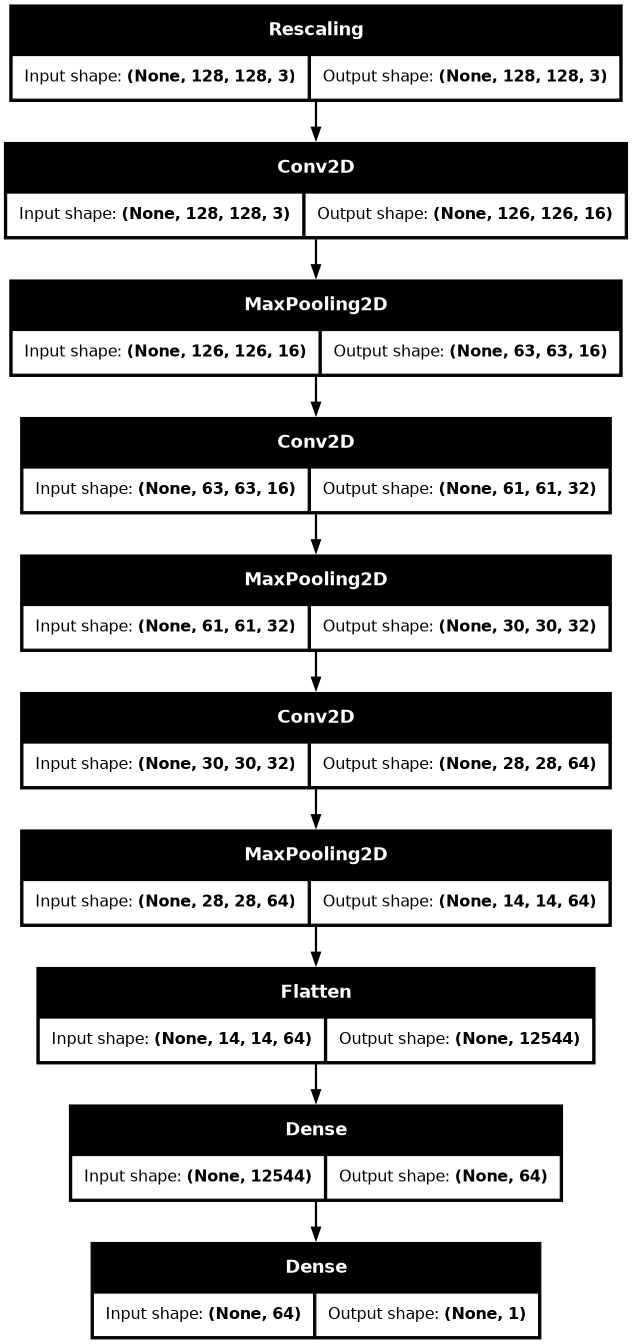

In [9]:
def build_cnn(name, dropout=False, l2=False, augment=False, gap=False):
    keras.utils.set_random_seed(SEED)
    reg = keras.regularizers.l2(1e-4) if l2 else None
    layers = [keras.Input((SIZE, SIZE, 3)), keras.layers.Rescaling(1 / 255)]
    if augment:  # active only in training
        layers += [keras.layers.RandomFlip("horizontal", seed=SEED), keras.layers.RandomRotation(0.05, seed=SEED),
                   keras.layers.RandomZoom(0.1, seed=SEED)]
    for filters in [16, 32, 64]:
        layers += [keras.layers.Conv2D(filters, 3, activation="relu", kernel_regularizer=reg), keras.layers.MaxPooling2D()]
    layers += [keras.layers.GlobalAveragePooling2D() if gap else keras.layers.Flatten(),
               keras.layers.Dense(64, activation="relu", kernel_regularizer=reg)]
    if dropout:
        layers.append(keras.layers.Dropout(0.5))
    layers.append(keras.layers.Dense(1, activation="sigmoid", kernel_regularizer=reg))
    model = keras.Sequential(layers, name="".join(c if c.isalnum() else "_" for c in name))
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return model

cnn = build_cnn("cnn_baseline")
layers_table = pd.DataFrame([{"layer": l.name, "type": type(l).__name__, "output shape": str(tuple(l.output.shape)),
                              "params": l.count_params()} for l in cnn.layers])
layers_table.to_csv(REPORTS / "final_cnn_layers.csv", index=False)
print(f"Total parameters: {cnn.count_params():,}")
display(layers_table)
keras.utils.plot_model(cnn, to_file=str(REPORTS / "final_cnn_architecture.png"), show_shapes=True, dpi=80)
ShowImage(str(REPORTS / "final_cnn_architecture.png"))

Loss: binary cross-entropy, -[y log(p) + (1 - y) log(1 - p)], where p is the sigmoid output, the predicted probability of Photo.
It is small when the model gives a high probability to the true class and grows without limit when it is confidently wrong.
It is the standard loss for a single sigmoid output and matches the PR-AUC view of the problem, which uses probabilities rather than hard labels.

Optimizer: Adam updates each weight with its own step size, built from running averages of its past gradients and squared gradients.
This makes it work well without much tuning, so its default learning rate of 1e-3 is kept for every model trained from scratch.
The pretrained model in section 7 uses 1e-5 during fine-tuning, to avoid erasing what the ImageNet weights learned.

class_weight: Photo is about one quarter of the training images, so an unweighted loss would favour the non-Photo class.
Each class gets the weight n / (2 n_c), computed on the training set only, so that both classes count the same in total in the loss.
The same weights are given to validation as sample_weight so that the two losses stay comparable; test metrics are never weighted.

CNN baseline            :  131 s | 20 epochs |   826,529 params | train acc 0.9949 | val acc 0.8923 | val balanced acc 0.8586


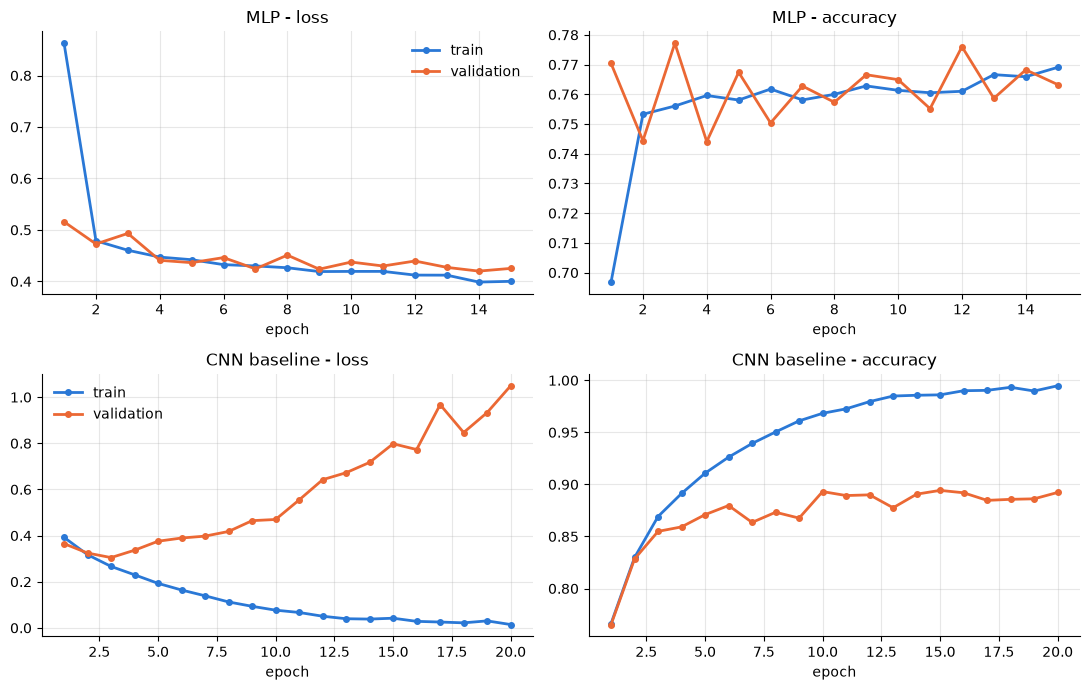

In [10]:
runs["baseline"] = train("CNN baseline", cnn, 20)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
plot_curves(runs["MLP"]["history"], "MLP", axes[0])
plot_curves(runs["baseline"]["history"], "CNN baseline", axes[1])
plt.tight_layout()
plt.savefig(REPORTS / "final_baseline_curves.png", dpi=120)
plt.show()

## 5. Bias and variance

The gap between train and validation accuracy measures variance (overfitting); a low train accuracy points to bias (underfitting).
Train accuracy is computed with the final weights on the whole training set, so dropout and augmentation do not lower it.

In [11]:
bv = {}
for k in ["MLP", "baseline"]:
    r, h = runs[k], runs[k]["history"]
    bv[k] = {"train accuracy": r["train_acc"], "validation accuracy": r["val"]["accuracy"],
             "gap": r["train_acc"] - r["val"]["accuracy"], "train loss (last)": h["loss"][-1],
             "val loss (last)": h["val_loss"][-1], "min val loss": min(h["val_loss"]),
             "epoch of min val loss": int(np.argmin(h["val_loss"])) + 1}
bv = pd.DataFrame(bv).T.rename(index={"baseline": "CNN baseline"})
bv.to_csv(REPORTS / "final_bias_variance.csv")
bv.round(4)

,train accuracy,validation accuracy,gap,train loss (last),val loss (last),min val loss,epoch of min val loss
MLP,0.7759,0.7633,0.0126,0.4001,0.4253,0.4200,14.0
CNN baseline,0.9949,0.8923,0.1026,0.0145,1.0493,0.3047,3.0


What I observe

Observed:
- CNN baseline: train accuracy 0.99 against 0.89 on validation, and the validation loss is lowest early, then rises.
- The MLP has a small gap but a low train accuracy.

Meaning: the CNN baseline probably has low bias and high variance (overfitting), while the MLP probably has high bias (underfitting).

## 6. Improvements to the CNN

Dropout zeroes half of the Dense(64) outputs at random during training and L2 adds a penalty on large weights; both limit how much the network can memorise.
Early stopping halts training when the validation loss has not improved for 3 epochs and restores the best weights.
Augmentation trains on randomly flipped, rotated and zoomed copies of the images, and global average pooling replaces Flatten by one average per feature map, which removes most Dense parameters.

Each variant is the baseline plus one change, trained from scratch with seed 42; a combined model then stacks the variants that pass the noise rule (the two best if none does).
Noise rule: with a single seed, run-to-run noise reaches about 3 points of balanced accuracy, so a change under 3 points is not counted as an improvement.
The best CNN variant is chosen on validation balanced accuracy only.

In [12]:
VARIANTS = {"a. dropout 0.5": dict(dropout=True), "b. L2 1e-4": dict(l2=True), "c. early stopping": dict(early_stopping=True),
            "d. augmentation": dict(augment=True), "e. global avg pooling": dict(gap=True)}

def run_variant(name, early_stopping=False, **flags):
    cb = [keras.callbacks.EarlyStopping("val_loss", patience=3, restore_best_weights=True)] if early_stopping else []
    return train(name, build_cnn(name, **flags), 20, cb)

for name, flags in VARIANTS.items():
    runs[name] = run_variant(name, **flags)

base_bacc = runs["baseline"]["val"]["balanced_acc"]
gain = {k: runs[k]["val"]["balanced_acc"] - base_bacc for k in VARIANTS}
stacked = [k for k, g in gain.items() if g > NOISE] or sorted(gain, key=gain.get, reverse=True)[:2]
print("Stacked in the combined model:", stacked, "(above 3 points)" if any(g > NOISE for g in gain.values()) else "(none above 3 points: two best)")
runs["combined"] = run_variant("combined", **{k: v for s in stacked for k, v in VARIANTS[s].items()})

a. dropout 0.5          :  124 s | 20 epochs |   826,529 params | train acc 0.9587 | val acc 0.8900 | val balanced acc 0.8933


b. L2 1e-4              :  121 s | 20 epochs |   826,529 params | train acc 0.9573 | val acc 0.8796 | val balanced acc 0.8558


c. early stopping       :   41 s |  6 epochs |   826,529 params | train acc 0.8635 | val acc 0.8506 | val balanced acc 0.8741


d. augmentation         :  250 s | 20 epochs |   826,529 params | train acc 0.9253 | val acc 0.8925 | val balanced acc 0.8773


e. global avg pooling   :  134 s | 20 epochs |    27,809 params | train acc 0.8844 | val acc 0.8816 | val balanced acc 0.9002
Stacked in the combined model: ['a. dropout 0.5', 'e. global avg pooling'] (above 3 points)


combined                :  129 s | 20 epochs |    27,809 params | train acc 0.8934 | val acc 0.8867 | val balanced acc 0.8969


In [13]:
CNN_ROWS = ["baseline", *VARIANTS, "combined"]
rows = {}
for k in CNN_ROWS:
    r, d = runs[k], runs[k]["val"]["balanced_acc"] - base_bacc
    rows[k] = {"epochs": r["epochs"], "params": r["params"], "train accuracy": r["train_acc"],
               "validation accuracy": r["val"]["accuracy"], "gap": r["train_acc"] - r["val"]["accuracy"],
               "val balanced accuracy": r["val"]["balanced_acc"], "val F1 Photo": r["val"]["f1"],
               "change vs baseline (points)": 100 * d,
               "above noise (3 points)?": "-" if k == "baseline" else ("yes" if d > NOISE else "no")}
val_summary = pd.DataFrame(rows).T
val_summary.index.name = "variant"
val_summary.to_csv(REPORTS / "final_val_summary.csv")
num = val_summary.columns[2:-1]
val_summary[num] = val_summary[num].astype(float).round(4)
val_summary["change vs baseline (points)"] = val_summary["change vs baseline (points)"].round(2)
display(val_summary)

best_cnn = max(CNN_ROWS[1:], key=lambda k: runs[k]["val"]["balanced_acc"])
print("Best CNN variant on validation:", best_cnn)
for k in CNN_ROWS:  # free the models that are not evaluated on test
    if k not in ("baseline", best_cnn):
        runs[k]["model"] = None

,epochs,params,train accuracy,validation accuracy,gap,val balanced accuracy,val F1 Photo,change vs baseline (points),above noise (3 points)?
variant,,,,,,,,,
baseline,20,826529,0.9949,0.8923,0.1026,0.8586,0.7848,0.00,-
a. dropout 0.5,20,826529,0.9587,0.8900,0.0687,0.8933,0.8023,3.47,yes
b. L2 1e-4,20,826529,0.9573,0.8796,0.0778,0.8558,0.7690,-0.29,no
c. early stopping,6,826529,0.8635,0.8506,0.0129,0.8741,0.7535,1.54,no
d. augmentation,20,826529,0.9253,0.8925,0.0329,0.8773,0.7962,1.87,no
e. global avg pooling,20,27809,0.8844,0.8816,0.0029,0.9002,0.7969,4.16,yes
combined,20,27809,0.8934,0.8867,0.0067,0.8969,0.8006,3.83,yes


Best CNN variant on validation: e. global avg pooling


What I observe

Observed:
- Global average pooling, dropout and their combination pass the 3-point rule; global average pooling is the best (+4.2 points).
- L2, early stopping and augmentation stay within noise.

Meaning: reducing the capacity of the dense part probably helps by cutting overfitting; the ranking among the variants that pass is not conclusive with one seed.

## 7. Pretrained MobileNetV2

MobileNetV2 pretrained on ImageNet is used without its classifier (include_top=False, global average pooling), with its own preprocess_input inside the model to map 0-255 pixels to [-1, 1].
Phase 1 freezes the backbone (trainable=False, called with training=False) and trains only a Dropout(0.2) + Dense(1) head for 10 epochs at lr 1e-3.
Phase 2 unfreezes the last 30 backbone layers, keeps BatchNorm layers frozen, and trains 10 more epochs at lr 1e-5 so that the pretrained weights move only slightly.

In [14]:
keras.utils.set_random_seed(SEED)
try:
    backbone = keras.applications.MobileNetV2(input_shape=(SIZE, SIZE, 3), include_top=False, weights="imagenet", pooling="avg")
except Exception as e:
    print(f"ImageNet weights could not be loaded: {type(e).__name__}: {e}")
    raise
backbone.trainable = False
inputs = keras.Input((SIZE, SIZE, 3))
x = backbone(keras.applications.mobilenet_v2.preprocess_input(inputs), training=False)
outputs = keras.layers.Dense(1, activation="sigmoid")(keras.layers.Dropout(0.2)(x))
pretrained = keras.Model(inputs, outputs, name="mobilenetv2_transfer")

def compile_pretrained(lr):
    pretrained.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])

def n_trainable(m):
    return int(sum(np.prod(w.shape) for w in m.trainable_weights))

compile_pretrained(1e-3)
print(f"Phase 1: total {pretrained.count_params():,} | trainable {n_trainable(pretrained):,}")
phase = {"phase 1: frozen": train("phase 1: frozen", pretrained, 10)}
phase["phase 1: frozen"]["trainable"] = n_trainable(pretrained)
weights_phase1 = pretrained.get_weights()

backbone.trainable = True
for layer in backbone.layers[:-30]:
    layer.trainable = False
for layer in backbone.layers[-30:]:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
compile_pretrained(1e-5)  # recompile so the new trainable flags apply
print(f"Phase 2: total {pretrained.count_params():,} | trainable {n_trainable(pretrained):,}")
t = time.time()
h2 = pretrained.fit(X["train"], y["train"], validation_data=(X["val"], y["val"], sw_val), epochs=20, initial_epoch=10,
                    batch_size=BATCH, class_weight=cw, verbose=0)
val2 = evaluate(y["val"], pretrained.predict(X["val"], verbose=0), origin["val"])
phase["phase 2: fine-tuned"] = {"val": val2, "trainable": n_trainable(pretrained), "params": pretrained.count_params(),
                                "train_acc": ((pretrained.predict(X["train"], verbose=0).ravel() >= 0.5) == y["train"]).mean()}
print(f"Phase 2: {time.time() - t:.0f} s | val balanced acc {val2['balanced_acc']:.4f}")
history_pt = {k: phase["phase 1: frozen"]["history"][k] + h2.history[k] for k in h2.history}

Phase 1: total 2,259,265 | trainable 1,281


phase 1: frozen         :   96 s | 10 epochs | 2,259,265 params | train acc 0.9769 | val acc 0.9659 | val balanced acc 0.9617
Phase 2: total 2,259,265 | trainable 1,512,001


Phase 2: 99 s | val balanced acc 0.9773


,trainable params,total params,train accuracy,validation accuracy,gap,val balanced accuracy,val F1 Photo
phase,,,,,,,
phase 1: frozen,1281.0,2259265.0,0.9769,0.9659,0.011,0.9617,0.9328
phase 2: fine-tuned,1512001.0,2259265.0,1.0000,0.9830,0.017,0.9773,0.9657


Selected on validation: phase 2: fine-tuned | phase 2 minus phase 1: +1.56 points (noise threshold 3)


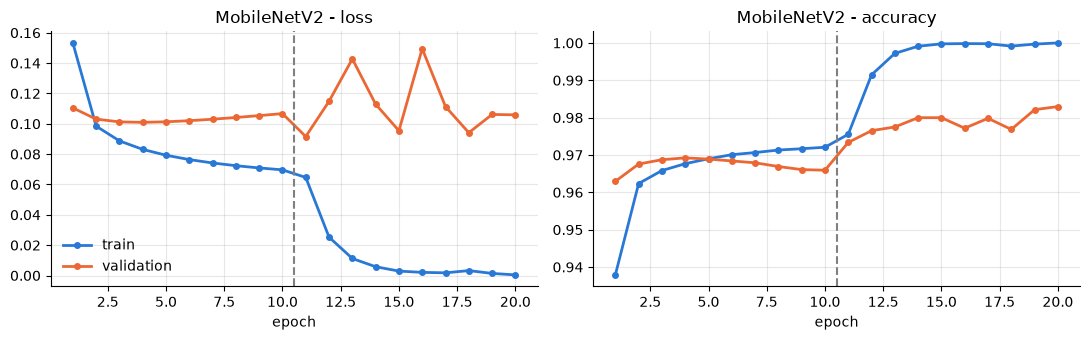

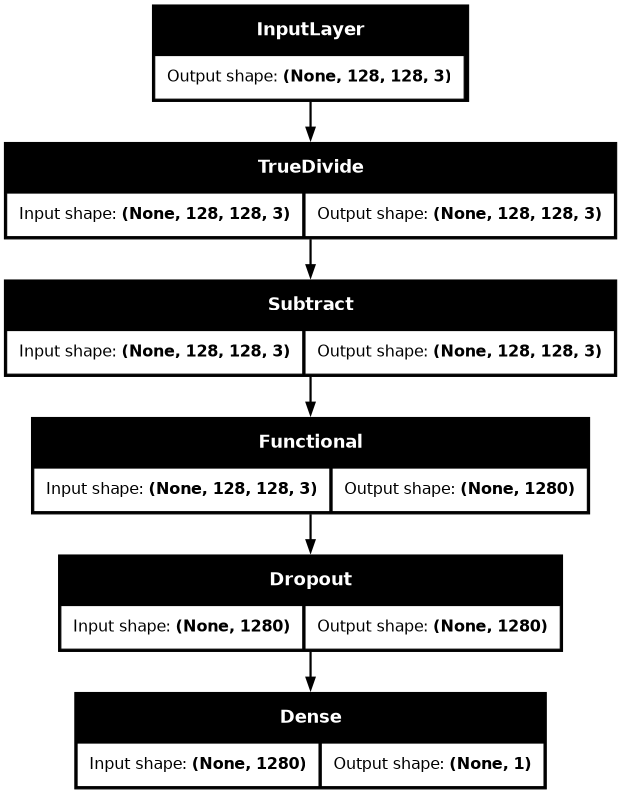

In [15]:
pt_table = pd.DataFrame({k: {"trainable params": r["trainable"], "total params": r["params"], "train accuracy": r["train_acc"],
                             "validation accuracy": r["val"]["accuracy"], "gap": r["train_acc"] - r["val"]["accuracy"],
                             "val balanced accuracy": r["val"]["balanced_acc"], "val F1 Photo": r["val"]["f1"]}
                         for k, r in phase.items()}).T
pt_table.index.name = "phase"
pt_table.to_csv(REPORTS / "final_pretrained_val.csv")
display(pt_table.astype(float).round(4))
best_phase = pt_table["val balanced accuracy"].idxmax()
if best_phase == "phase 1: frozen":
    pretrained.set_weights(weights_phase1)
d = 100 * (pt_table["val balanced accuracy"].iloc[1] - pt_table["val balanced accuracy"].iloc[0])
print(f"Selected on validation: {best_phase} | phase 2 minus phase 1: {d:+.2f} points (noise threshold 3)")

axes = plot_curves(history_pt, "MobileNetV2")
for ax in axes:
    ax.axvline(10.5, color="grey", ls="--")
plt.tight_layout()
plt.savefig(REPORTS / "final_pretrained_curves.png", dpi=120)
plt.show()
pretrained.save(MODELS / "final_pretrained.keras")
keras.utils.plot_model(pretrained, to_file=str(REPORTS / "final_pretrained_architecture.png"), show_shapes=True, expand_nested=False, dpi=80)
ShowImage(str(REPORTS / "final_pretrained_architecture.png"))

The dashed line marks the start of fine-tuning; losses are class-weighted on both sides and accuracies are plain.

What I observe

Observed:
- The frozen backbone, with 1,281 trainable weights, already reaches 0.96 validation balanced accuracy.
- Fine-tuning adds a gain within noise, with a small train-validation gap.

Meaning: the ImageNet features probably carry most of the useful signal; the fine-tuning gain is not conclusive.

## 8. Final evaluation on the test set

Each neural network is evaluated once here, at threshold 0.5, on the natural test distribution; the two baselines were scored once in section 3.
The best CNN variant and the pretrained phase were chosen on validation before this cell.

In [16]:
NETS = {"MLP": runs["MLP"]["model"], "CNN baseline": runs["baseline"]["model"],
        f"CNN best variant ({best_cnn})": runs[best_cnn]["model"], f"MobileNetV2 ({best_phase})": pretrained}
for k, m in NETS.items():
    test_eval[k] = evaluate(y["test"], m.predict(X["test"], verbose=0), origin["test"])
test_table = pd.DataFrame({k: {m: v[m] for m in METRICS} for k, v in test_eval.items()}).T
test_table.index.name = "model"
test_table.round(4).to_csv(REPORTS / "final_test_results.csv")
print(f"Test set (n = {len(y['test'])})")
test_table.round(4)

Test set (n = 6046)


,precision,recall,f1,balanced_acc,pr_auc,accuracy
model,,,,,,
majority,0.0000,0.0000,0.0000,0.5000,0.2479,0.7521
decision tree (metadata),0.9641,0.9853,0.9746,0.9866,0.9849,0.9873
MLP,0.5060,0.8999,0.6478,0.8051,0.6324,0.7574
CNN baseline,0.7734,0.7992,0.7861,0.8610,0.8324,0.8922
CNN best variant (e. global avg pooling),0.6740,0.9406,0.7853,0.8953,0.9023,0.8725
MobileNetV2 (phase 2: fine-tuned),0.9635,0.9693,0.9664,0.9786,0.9930,0.9833


What I observe

Observed:
- MobileNetV2 reaches 0.98 test balanced accuracy, against 0.90 for the best CNN trained from scratch.
- It stays below the metadata tree, by less than 3 points.

Meaning: pretrained features probably transfer well to this task; the gap with the tree is not conclusive.

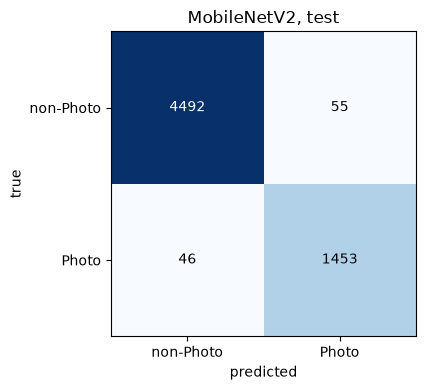

,majority,decision tree (metadata),MLP,CNN baseline,CNN best variant (e. global avg pooling),MobileNetV2 (phase 2: fine-tuned)
origin,,,,,,
Painting,0.0,0.0320,0.6927,0.2033,0.4007,0.0333
Photo,1.0,0.0147,0.1001,0.2008,0.0594,0.0307
Schematics,0.0,0.0052,0.2073,0.0344,0.0606,0.0037
Sketch,0.0,0.0000,0.0000,0.0000,0.0000,0.0000
Text,0.0,0.0000,0.0007,0.0000,0.0000,0.0000


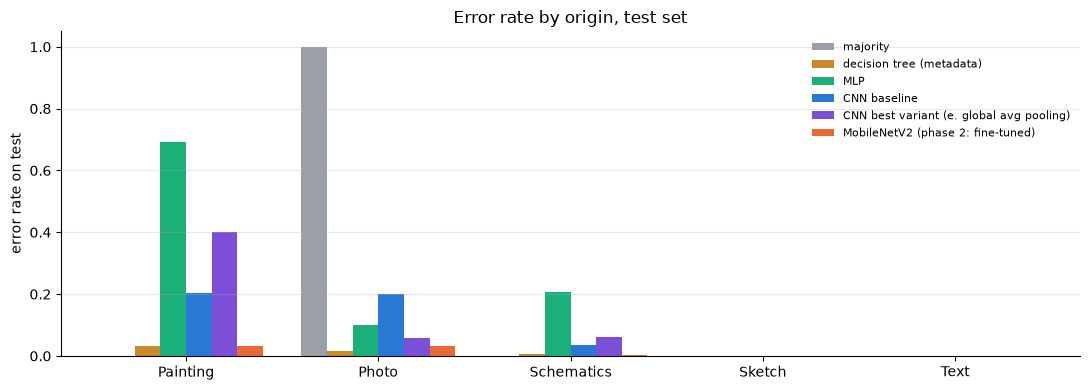

In [17]:
k_pt = f"MobileNetV2 ({best_phase})"
cm = test_eval[k_pt]["cm"]
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["non-Photo", "Photo"])
ax.set_yticks([0, 1], ["non-Photo", "Photo"])
ax.set(xlabel="predicted", ylabel="true", title="MobileNetV2, test")
plt.tight_layout()
plt.savefig(REPORTS / "final_pretrained_confusion.png", dpi=120)
plt.show()

err = pd.DataFrame({k: v["error_by_origin"] for k, v in test_eval.items()})
err.index.name = "origin"
err.round(4).to_csv(REPORTS / "final_error_by_origin.csv")
display(err.round(4))
colors = ["#9aa0a6", "#c98a2b", "#1baf7a", "#2a78d6", "#7b4fd6", "#eb6834"]
ax = err.plot.bar(figsize=(11, 4), color=colors, rot=0, width=0.8)
ax.set(ylabel="error rate on test", title="Error rate by origin, test set", xlabel="")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(REPORTS / "final_error_by_origin.png", dpi=120)
plt.show()

What I observe

Observed:
- Painting is the hardest origin for every network trained from scratch, up to 0.69 error for the MLP.
- MobileNetV2 brings Painting error down to 0.03.

Meaning: telling paintings from photos is probably the core difficulty, and ImageNet features seem to handle it much better.

## 9. Key takeaways

- Format alone (size and colour mode) nearly separates the classes, so the metadata tree, not the majority class, is the bar to beat.
- A CNN trained from scratch overfits; reducing capacity (global average pooling, dropout) helps beyond noise on validation.
- The pretrained MobileNetV2 is the best network on test, at 0.98 balanced accuracy.
- Painting is the main source of errors for the networks trained from scratch.
- Interpretation: part of every score may come from format cues (to check with a size-matched test).

## 10. Limits and reproducibility

In [18]:
print(f"Total notebook runtime: {(time.time() - T0) / 60:.1f} min on {GPU_NAME}")

Total notebook runtime: 20.2 min on NVIDIA GeForce RTX 5060 Laptop GPU


- Single seed (42): run-to-run noise reaches about 3 points of balanced accuracy, so differences under 3 points are not conclusive; more seeds were not run.
- GPU non-determinism: even with seed 42, two runs give slightly different numbers, and the ranking of close variants can change.
- Shortcut not tested: a size-matched test set would show whether the networks rely on image size and format, as the metadata tree does.
- Resizing to 128x128 ignores the aspect ratio and distorts shapes.
- The ImageNet weights are downloaded on first run (internet needed once), and ImageNet's many photos may favour MobileNetV2.
- Runtime and hardware: about 20 minutes on one NVIDIA GeForce RTX 5060 Laptop GPU (cell above), plus image loading on the very first run.